In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
!ls src/experiments/09_11_2026_grayscale_best_models_long_runs/

evaluate.py  evaluation_results.csv  grids  README.md  train_models.py


In [45]:
df = pd.read_csv("../src/experiments/09_11_2026_grayscale_best_models_long_runs/evaluation_results.csv")

In [48]:
df_bis = pd.read_csv("../src/experiments/08_11_2026_grayscale_grid_search/evaluation_results.csv")

In [78]:
def stripplot_optimizer(df):
    sns.boxplot(x='Optimizer', y='FID_Score', data=df, palette=['#2196F3', '#FF9800'], width=0.4)
    sns.stripplot(x='Optimizer', y='FID_Score', data=df, color='black', size=6, jitter=True, zorder=5)
    plt.title('Adam vs AdamW - Distribution des FID Scores')
    plt.ylabel('FID Score')
    plt.xlabel('Optimizer')
    plt.tight_layout()
    plt.savefig("../figures/grayscale_optimizer_comparison.png")
    plt.show()

In [52]:
gray_df = pd.concat([df, df_bis])

/tmp/ipykernel_19276/1191328655.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Optimizer', y='FID_Score', data=df, palette=['#2196F3', '#FF9800'], width=0.4)


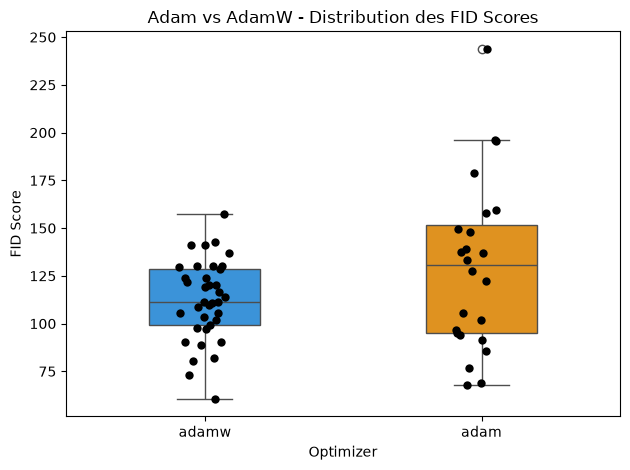

In [80]:
stripplot_optimizer(gray_df[gray_df["Scheduler"] != "cosine"])

In [12]:
from torchvision import datasets
from pathlib import Path

In [13]:
DS_PATH = Path("dataset/data/mc-items-32x/310p")
TRAIN_PATH = DS_PATH / "train"
TEST_PATH = DS_PATH / "test"

In [14]:
train_ds = datasets.ImageFolder(TRAIN_PATH)
test_ds = datasets.ImageFolder(TEST_PATH)

In [84]:
from collections import defaultdict
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image
import numpy as np

def plot_distrib(ds, zoom=1.5):
    label_counter = defaultdict(int)
    first_image_for_class = {}

    for path, label in ds.samples:
        class_name = ds.classes[label]
        label_counter[class_name] += 1
        if class_name not in first_image_for_class:
            first_image_for_class[class_name] = path

    labels = list(label_counter.keys())
    counts = list(label_counter.values())
    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(23,4))
    ax.bar(x, counts)

    ax.set_xticks(x)
    ax.set_xticklabels([""] * len(labels))  # hide text labels
    ax.margins(x=0)
    ax.set_xlim(-0.75, len(labels) - 0.25)

    for i, label in enumerate(labels):
        img = Image.open(first_image_for_class[label]).convert("RGBA")
        imagebox = OffsetImage(np.array(img), zoom=zoom)
        ab = AnnotationBbox(
            imagebox, (i, 0),
            xybox=(0, -5),
            xycoords='data',
            boxcoords="offset points",
            frameon=False,
            box_alignment=(0.5, 1)
        )
        ax.add_artist(ab)

    plt.tight_layout()
    plt.savefig("../figures/repartition.png")
    plt.show()


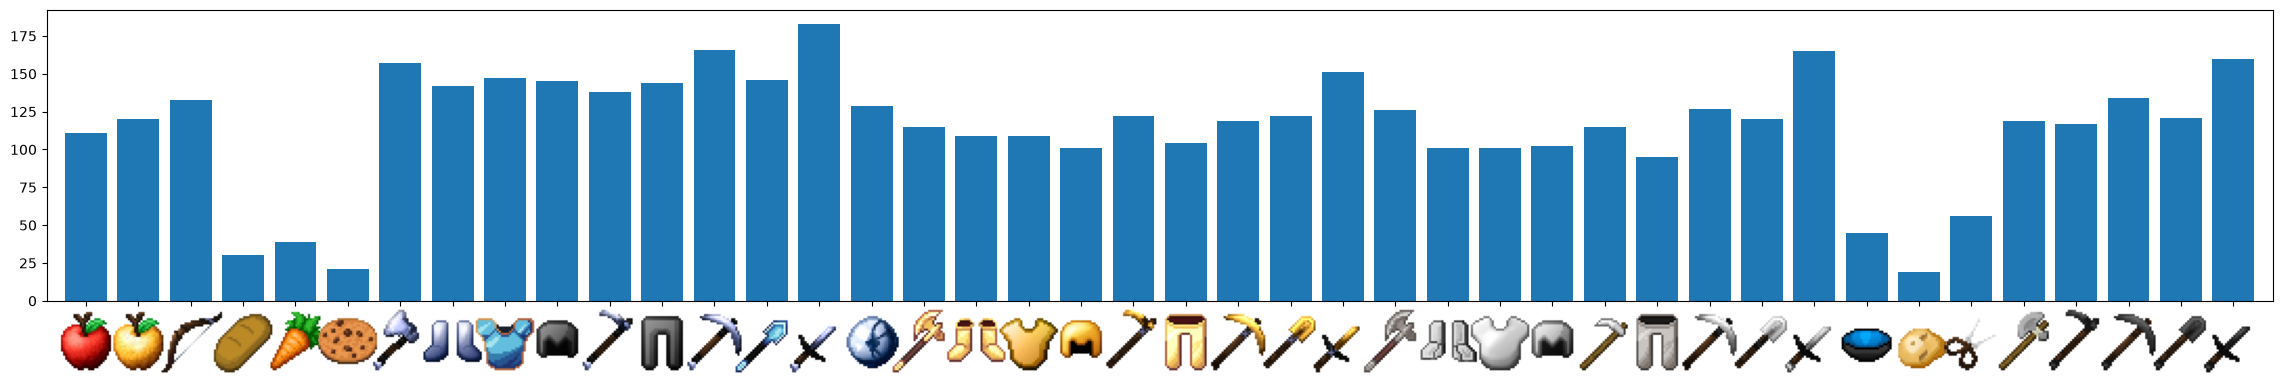

In [85]:
plot_distrib(train_ds)